# 1. BloodMNIST Part A — Custom CNN and Data Augmentation

## Research question

Does random data augmentation improve how well our custom CNN classifies the eight BloodMNIST cell types from 128 × 128 RGB images?

## Experiment design

We train the same CNN from scratch with and without training augmentation. We use at least three paired seeds and match the initial weights, training image order, architecture, optimizer, loss, batch size, and epoch budget within each pair. We use identical deterministic preprocessing for validation and test and verify that PyTorch detects a CUDA GPU before full training.

## Data integrity

We start with the official train, validation, and test splits. We audit the raw images for exact pixel duplicates within and across splits, keeping rows in train → validation → test priority and recording exclusions and label conflicts. We check whether patient or source identifiers are available and whether a near-duplicate audit is feasible. We compute RGB normalization statistics using only the retained training images.

## Evaluation and reproducibility

We select checkpoints using validation macro F1 and freeze the experiment settings before evaluating the test set in a separate cell. We report accuracy, macro F1, balanced accuracy, per-class metrics, and paired differences between the two conditions. We save the split audit, run configuration, checkpoints, training histories, metrics, predictions, and plots in a persistent results folder.

In [11]:
# 2. Verify C%pip install medmnistUDA in the Compute Data Lab notebook kernel

import torch

print("PyTorch version:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda:0")
    print("GPU:", torch.cuda.get_device_name(device))
    print("CUDA test tensor:", torch.zeros(1, device=device).device)

PyTorch version: 2.9.1+cu128
PyTorch CUDA build: 12.8
CUDA available: True
GPU: NVIDIA RTX A6000
CUDA test tensor: cuda:0


In [12]:
%pip install medmnist

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 80.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [medmnist]4/6 [scikit-image]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Load the official BloodMNIST splits

We download BloodMNIST at 128 × 128 RGB and load its official training, validation, and test splits. We check the image counts and raw array shapes before auditing duplicates or applying any preprocessing.

In [13]:
from medmnist import BloodMNIST

official_datasets = {
    split: BloodMNIST(split=split, size=128, download=True)
    for split in ("train", "val", "test")
}

for split, dataset in official_datasets.items():
    print(f"{split}: {len(dataset):,} images, raw shape {dataset.imgs.shape}")

100%|██████████| 569M/569M [00:14<00:00, 40.6MB/s] 


train: 11,959 images, raw shape (11959, 128, 128, 3)
val: 1,712 images, raw shape (1712, 128, 128, 3)
test: 3,421 images, raw shape (3421, 128, 128, 3)


In [14]:
import numpy as np

expected_sizes = {"train": 11959, "val": 1712, "test": 3421}
expected_labels = set(range(8))

for split, dataset in official_datasets.items():
    images = dataset.imgs
    labels = dataset.labels
    count = expected_sizes[split]

    assert images.shape == (count, 128, 128, 3), (split, images.shape)
    assert images.dtype == np.uint8, (split, images.dtype)
    assert labels.shape in {(count,), (count, 1)}, (split, labels.shape)
    assert np.issubdtype(labels.dtype, np.integer), (split, labels.dtype)

    observed_labels = set(np.unique(labels).tolist())
    assert observed_labels == expected_labels, (split, observed_labels)

    print(f"{split}: {count:,} RGB images, all 8 classes present")

train: 11,959 RGB images, all 8 classes present
val: 1,712 RGB images, all 8 classes present
test: 3,421 RGB images, all 8 classes present


## 3. Audit exact duplicates in the raw images

We compare raw pixel values before preprocessing. We check the training split first, then validation, then test. Within each split, we use the original row order. For each group of pixel-identical images, we keep the first occurrence in its original split and exclude the later occurrences.

If identical images have different labels, we keep the label of the first occurrence and record the conflict. Validation and test labels never influence which training rows we keep.

We verify that no exact pixel duplicates remain within or across the retained splits. We save a split manifest in `results/` with the original row indices, exclusion reasons, and before-and-after counts.

In [15]:
import hashlib
import json
from pathlib import Path

RESULTS_DIR = Path.home() / "BloodMNIST_Part_A_outputs" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

split_order = ("train", "val", "test")
first_seen = {}
retained_indices = {}
split_manifest = {
    "priority": list(split_order),
    "policy": "Keep the earliest identical image in split and original row order.",
    "label_conflict_policy": "Keep the first row and its original label. Record both labels.",
    "splits": {},
}

for split in split_order:
    dataset = official_datasets[split]
    kept_rows = []
    excluded_rows = []

    for row_id, image in enumerate(dataset.imgs):
        fingerprint = hashlib.sha256(image.tobytes()).digest()
        label = int(dataset.labels[row_id].item())
        first = first_seen.get(fingerprint)

        if first is None:
            first_seen[fingerprint] = (split, row_id, label)
            kept_rows.append(row_id)
            continue

        kept_split, kept_row_id, kept_label = first
        assert np.array_equal(
            image, official_datasets[kept_split].imgs[kept_row_id]
        ), "SHA-256 collision between different images"

        excluded_rows.append({
            "original_row_id": row_id,
            "label": label,
            "reason": (
                "exact_duplicate_within_split"
                if kept_split == split
                else "exact_duplicate_across_splits"
            ),
            "kept_split": kept_split,
            "kept_original_row_id": kept_row_id,
            "kept_label": kept_label,
            "label_conflict": label != kept_label,
        })

    retained_indices[split] = np.array(kept_rows, dtype=np.int64)
    split_manifest["splits"][split] = {
        "count_before": len(dataset),
        "count_after": len(kept_rows),
        "count_excluded": len(excluded_rows),
        "label_conflicts": sum(row["label_conflict"] for row in excluded_rows),
        "retained_original_row_ids": kept_rows,
        "exclusions": excluded_rows,
    }

retained_fingerprints = set()
for split in split_order:
    for row_id in retained_indices[split]:
        image = official_datasets[split].imgs[row_id]
        fingerprint = hashlib.sha256(image.tobytes()).digest()
        assert fingerprint not in retained_fingerprints, (split, int(row_id))
        retained_fingerprints.add(fingerprint)

split_manifest["zero_exact_duplicates_verified"] = True
manifest_path = RESULTS_DIR / "split_manifest.json"
manifest_path.write_text(json.dumps(split_manifest, indent=2) + "\n", encoding="utf-8")

for split, summary in split_manifest["splits"].items():
    print(
        f"{split}: {summary['count_before']:,} → {summary['count_after']:,} "
        f"({summary['count_excluded']:,} excluded, "
        f"{summary['label_conflicts']:,} label conflicts)"
    )

print("Zero exact duplicates remain within or across retained splits.")
print("Saved:", manifest_path)

train: 11,959 → 11,951 (8 excluded, 0 label conflicts)
val: 1,712 → 1,709 (3 excluded, 0 label conflicts)
test: 3,421 → 3,415 (6 excluded, 1 label conflicts)
Zero exact duplicates remain within or across retained splits.
Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/split_manifest.json


In [16]:
from zipfile import ZipFile

archive_path = Path(official_datasets["train"].root) / "bloodmnist_128.npz"

with ZipFile(archive_path) as archive:
    archive_fields = sorted(
        Path(name).stem for name in archive.namelist() if name.endswith(".npy")
    )

print("Dataset archive fields:", archive_fields)

Dataset archive fields: ['test_images', 'test_labels', 'train_images', 'train_labels', 'val_images', 'val_labels']


In [17]:
split_manifest["leakage_checks"] = {
    "archive_fields": archive_fields,
    "exact_pixel_duplicates": {
        "status": "passed",
        "scope": "Within and across all retained splits at 128 × 128 RGB.",
    },
    "patient_and_source_overlap": {
        "status": "unverifiable",
        "reason": "The downloaded archive contains image and label arrays only.",
    },
    "near_duplicate_overlap": {
        "status": "not_tested",
        "feasibility": (
            "Image similarity can flag candidate pairs for visual review. "
            "It cannot verify patient or source identity."
        ),
    },
}

manifest_path.write_text(
    json.dumps(split_manifest, indent=2) + "\n",
    encoding="utf-8",
)
print("Updated:", manifest_path)

Updated: /home/jovyan/BloodMNIST_Part_A_outputs/results/split_manifest.json


## 4. Explore the retained BloodMNIST images

We show one retained training image from each of the eight blood cell classes. After duplicate removal, we calculate each class’s count and percentage within the training, validation, and test splits.

We save the image grid and class-distribution plot as PNGs and the counts and percentages as a CSV in `results/`.

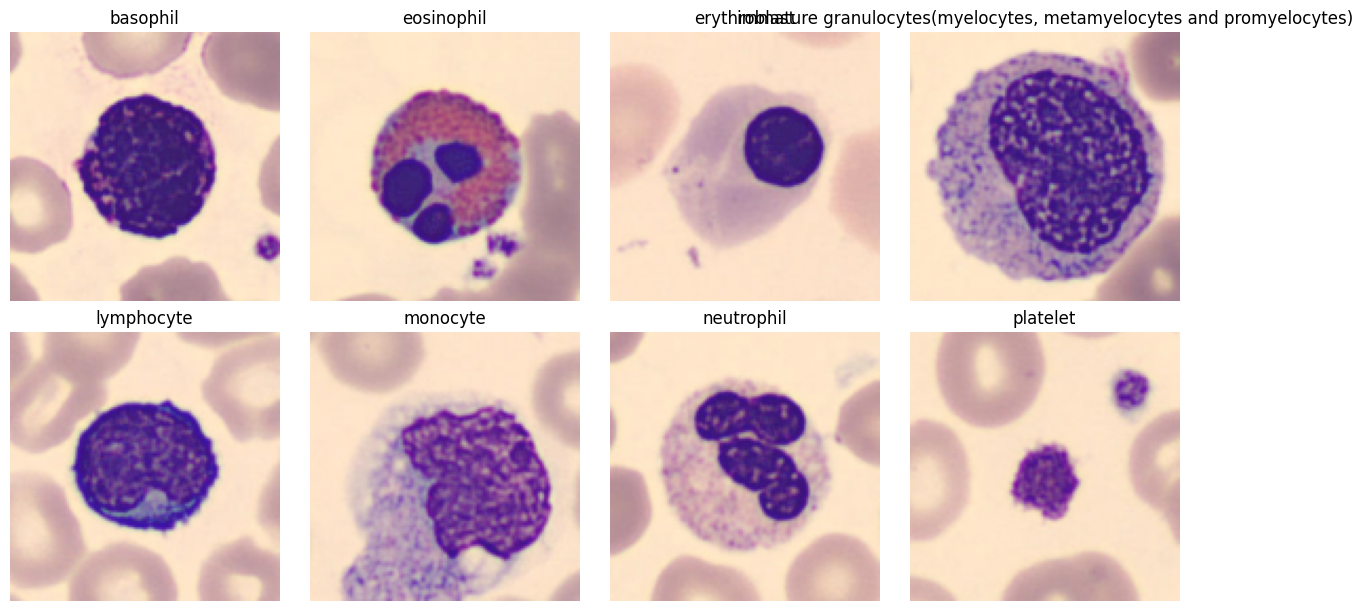

Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/bloodmnist_class_grid.png


In [18]:
import matplotlib.pyplot as plt

train_data = official_datasets["train"]
train_rows = retained_indices["train"]
train_labels = train_data.labels.reshape(-1)

class_names = {
    int(label): name for label, name in train_data.info["label"].items()
}

fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained")

for class_id, ax in enumerate(axes.flat):
    matching_rows = train_rows[train_labels[train_rows] == class_id]
    assert matching_rows.size > 0, f"No retained training images for class {class_id}"

    row_id = int(matching_rows[0])
    ax.imshow(train_data.imgs[row_id])
    ax.set_title(class_names[class_id])
    ax.axis("off")

grid_path = RESULTS_DIR / "bloodmnist_class_grid.png"
fig.savefig(grid_path, dpi=200)
plt.show()
plt.close(fig)

print("Saved:", grid_path)

count                \
split                                                train    val   test   
class_name                                                                 
basophil                                             850.0  121.0  241.0   
eosinophil                                          2179.0  310.0  622.0   
erythroblast                                        1085.0  155.0  311.0   
immature granulocytes(myelocytes, metamyelocyte...  2023.0  290.0  579.0   
lymphocyte                                           849.0  122.0  243.0   
monocyte                                             992.0  143.0  284.0   
neutrophil                                          2330.0  333.0  665.0   
platelet                                            1643.0  235.0  470.0   

                                                   percentage                
split                                                   train    val   test  
class_name                                                                   
basophil                                                 7.11   7.08   7.06  
eosinophil                                              18.23  18.14  18.21  
erythroblast                                             9.08   9.07   9.11  
immature granulocytes(myelocytes, metamyelocyte...      16.93  16.97  16.95  
lymphocyte                                               7.10   7.14   7.12  
monocyte                                                 8.30   8.37   8.32  
neutrophil                                              19.50  19.49  19.47  
platelet                                                13.75  13.75  13.76

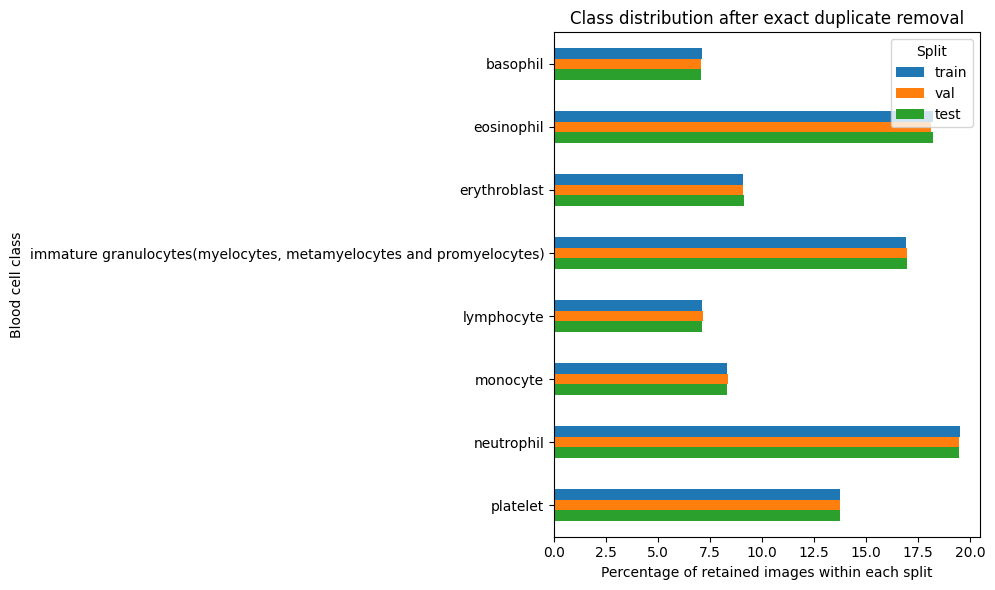

Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/class_distribution.csv
Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/class_distribution.png


In [19]:
import pandas as pd
from IPython.display import display

distribution_rows = []

for split in split_order:
    labels = official_datasets[split].labels.reshape(-1)
    kept_labels = labels[retained_indices[split]]
    counts = np.bincount(kept_labels, minlength=len(class_names))

    for class_id, count in enumerate(counts):
        distribution_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_names[class_id],
            "count": int(count),
            "percentage": 100 * count / len(kept_labels),
        })

class_distribution = pd.DataFrame(distribution_rows)
csv_path = RESULTS_DIR / "class_distribution.csv"
class_distribution.to_csv(csv_path, index=False)

display(
    class_distribution.pivot(
        index="class_name",
        columns="split",
        values=["count", "percentage"],
    ).reindex(columns=split_order, level="split").round(2)
)

plot_data = class_distribution.pivot(
    index="class_name", columns="split", values="percentage"
).reindex(index=list(class_names.values()), columns=split_order)

ax = plot_data.plot.barh(figsize=(10, 6))
ax.invert_yaxis()
ax.set_title("Class distribution after exact duplicate removal")
ax.set_xlabel("Percentage of retained images within each split")
ax.set_ylabel("Blood cell class")
ax.legend(title="Split")

fig = ax.get_figure()
fig.tight_layout()
plot_path = RESULTS_DIR / "class_distribution.png"
fig.savefig(plot_path, dpi=200)
plt.show()
plt.close(fig)

print("Saved:", csv_path)
print("Saved:", plot_path)

## 5. Prepare image normalization and augmentation

We calculate the mean and standard deviation of each RGB channel using only the retained training images, processed in batches. We use these same statistics to normalize images in both training conditions and in validation and test.

In the augmented run, we apply random transformations to training images before normalization. We use identical deterministic preprocessing for validation and test in both runs. We display and save an augmentation preview using retained training images.

In [20]:
stats_batch_size = 64
channel_sum = np.zeros(3, dtype=np.float64)
channel_squared_sum = np.zeros(3, dtype=np.float64)
pixel_count = 0

for start in range(0, len(train_rows), stats_batch_size):
    batch_rows = train_rows[start:start + stats_batch_size]
    pixels = train_data.imgs[batch_rows].reshape(-1, 3).astype(np.float64)
    pixels /= 255.0

    channel_sum += pixels.sum(axis=0)
    channel_squared_sum += np.square(pixels).sum(axis=0)
    pixel_count += len(pixels)

rgb_mean = (channel_sum / pixel_count).tolist()
rgb_std = np.sqrt(
    channel_squared_sum / pixel_count - np.square(rgb_mean)
).tolist()

normalization_path = RESULTS_DIR / "normalization.json"
normalization_path.write_text(
    json.dumps({
        "split": "train",
        "retained_images": len(train_rows),
        "channel_order": ["R", "G", "B"],
        "pixel_scale": "[0, 1]",
        "mean": rgb_mean,
        "std": rgb_std,
    }, indent=2) + "\n",
    encoding="utf-8",
)

print("RGB mean:", np.round(rgb_mean, 6))
print("RGB std:", np.round(rgb_std, 6))
print("Saved:", normalization_path)

RGB mean: [0.796079 0.659648 0.696372]
RGB std: [0.225759 0.258621 0.095717]
Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/normalization.json


In [21]:
from torchvision import transforms

augmentation_settings = {
    "horizontal_flip_probability": 0.5,
    "vertical_flip_probability": 0.5,
}

train_augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(
        p=augmentation_settings["horizontal_flip_probability"]
    ),
    transforms.RandomVerticalFlip(
        p=augmentation_settings["vertical_flip_probability"]
    ),
])

deterministic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=rgb_mean, std=rgb_std),
])

augmented_train_transform = transforms.Compose([
    train_augmentation,
    deterministic_transform,
])

print("Training without augmentation, validation, and test: tensor + RGB normalization")
print("Training with augmentation: random flips + tensor + RGB normalization")

Training without augmentation, validation, and test: tensor + RGB normalization
Training with augmentation: random flips + tensor + RGB normalization


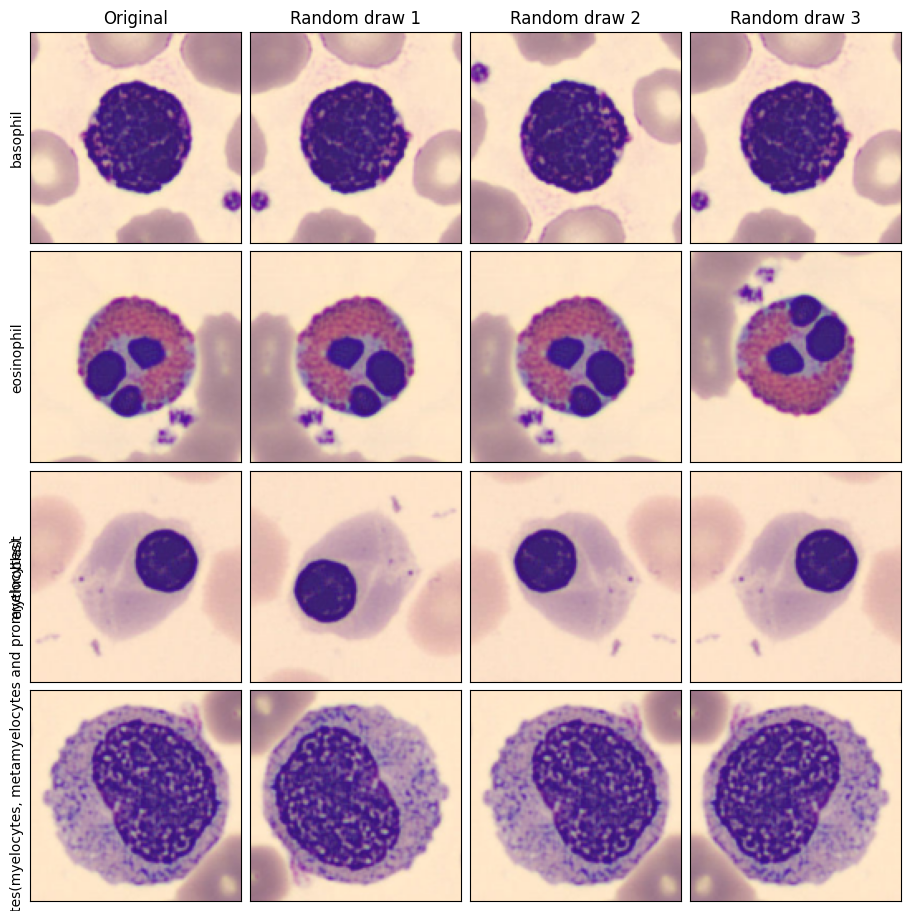

Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/augmentation_preview.png


In [22]:
# Show and save the augmentation preview
from PIL import Image

fig, axes = plt.subplots(4, 4, figsize=(9, 9), layout="constrained")
column_titles = ["Original", "Random draw 1", "Random draw 2", "Random draw 3"]

with torch.random.fork_rng(devices=[]):
    torch.random.default_generator.manual_seed(0)

    for class_id, row_axes in enumerate(axes):
        matching_rows = train_rows[train_labels[train_rows] == class_id]
        row_id = int(matching_rows[0])
        original = Image.fromarray(train_data.imgs[row_id])
        examples = [original] + [train_augmentation(original) for _ in range(3)]

        for column, (ax, example) in enumerate(zip(row_axes, examples)):
            ax.imshow(example)
            ax.set_xticks([])
            ax.set_yticks([])
            if class_id == 0:
                ax.set_title(column_titles[column])
            if column == 0:
                ax.set_ylabel(class_names[class_id])

preview_path = RESULTS_DIR / "augmentation_preview.png"
fig.savefig(preview_path, dpi=200)
plt.show()
plt.close(fig)

print("Saved:", preview_path)

## 6. Build the custom CNN

We build a CNN with three convolutional blocks containing 16, 32, and 64 filters. Each block uses a 3 × 3 convolution, batch normalization, ReLU, and 2 × 2 max pooling. The convolutions learn image features, and max pooling halves the height and width after each block.

We use adaptive average pooling to reduce the final feature maps to 4 × 4, then flatten them and use a linear layer to produce eight logits, one per blood cell class.

We train this architecture from scratch in both conditions and verify that a batch of 128 × 128 RGB images produces eight logits per image.

In [23]:
from torch import nn


class BloodCellCNN(nn.Module):
    def __init__(self):
        super().__init__()

        layers = []
        for in_channels, out_channels in [(3, 16), (16, 32), (32, 64)]:
            layers.extend([
                nn.Conv2d(
                    in_channels, out_channels, kernel_size=3, padding=1, bias=False
                ),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
            ])

        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 8),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


assert torch.cuda.is_available(), "CUDA is unavailable in this notebook kernel."

shape_check_model = BloodCellCNN().to(device).eval()
example_images = torch.zeros((2, 3, 128, 128), device=device)

with torch.inference_mode():
    logits = shape_check_model(example_images)

assert logits.shape == (2, 8), tuple(logits.shape)

parameter_count = sum(
    parameter.numel()
    for parameter in shape_check_model.parameters()
    if parameter.requires_grad
)

print("Input shape:", tuple(example_images.shape))
print("Output shape:", tuple(logits.shape))
print("Output device:", logits.device)
print(f"Trainable parameters: {parameter_count:,}")

Input shape: (2, 3, 128, 128)
Output shape: (2, 8)
Output device: cuda:0
Trainable parameters: 31,896


## 7. Configure the paired experiment

We use seeds 42, 43, and 44 to train six models. For each seed, we initialize the CNN once and start both runs from the same initial weights. We give the two runs the same training image order in each epoch and use the same architecture, optimizer, loss, batch size, and epoch budget. Random flips are the only experimental change.

We keep the random draws for augmentation independent of the training image order. We use the same deterministic preprocessing for validation and select each run’s best checkpoint by validation macro F1.

We save the experiment settings, package and dataset versions, GPU details, RGB normalization values, and augmentation settings in `results/`.

In [24]:
from importlib.metadata import version

SEEDS = (42, 43, 44)
CONDITIONS = ("without_augmentation", "with_augmentation")

BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

dataset_info = train_data.info
run_config = {
    "dataset": {
        "name": "BloodMNIST",
        "collection": "MedMNIST v2",
        "input_size": [128, 128, 3],
        "archive": archive_path.name,
        "source_url": dataset_info.get("url_128"),
        "published_md5": dataset_info.get("MD5_128"),
        "split_manifest_sha256": hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
        "class_names": [class_names[class_id] for class_id in range(8)],
    },
    "model": {
        "name": BloodCellCNN.__name__,
        "convolution_channels": [16, 32, 64],
        "adaptive_pool_size": [4, 4],
        "trainable_parameters": parameter_count,
    },
    "training": {
        "seeds": list(SEEDS),
        "conditions": list(CONDITIONS),
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "optimizer": "AdamW",
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "loss": "CrossEntropyLoss",
        "checkpoint_metric": "validation_macro_f1",
        "checkpoint_tie_break": "earliest_epoch",
    },
    "preprocessing": {
        "rgb_mean": rgb_mean,
        "rgb_std": rgb_std,
        "augmented_training_only": augmentation_settings,
    },
    "environment": {
        "packages": {
            package: version(package)
            for package in (
                "medmnist", "torch", "torchvision", "numpy",
                "pandas", "scikit-learn", "matplotlib", "Pillow",
            )
        },
        "device": str(device),
        "gpu": torch.cuda.get_device_name(device),
        "pytorch_cuda_build": torch.version.cuda,
        "cudnn_version": torch.backends.cudnn.version(),
        "cudnn_deterministic": torch.backends.cudnn.deterministic,
        "cudnn_benchmark": torch.backends.cudnn.benchmark,
    },
}

config_path = RESULTS_DIR / "run_config.json"
config_path.write_text(
    json.dumps(run_config, indent=2) + "\n",
    encoding="utf-8",
)

print("Paired seeds:", SEEDS)
print("GPU:", run_config["environment"]["gpu"])
print("Saved:", config_path)

Paired seeds: (42, 43, 44)
GPU: NVIDIA RTX A6000
Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/run_config.json


In [25]:
from torch.utils.data import DataLoader, Dataset, RandomSampler


class RetainedBloodMNIST(Dataset):
    def __init__(self, split, transform):
        self.source = official_datasets[split]
        self.row_ids = retained_indices[split]
        self.transform = transform

    def __len__(self):
        return len(self.row_ids)

    def __getitem__(self, index):
        row_id = int(self.row_ids[index])
        image = Image.fromarray(self.source.imgs[row_id])
        label = int(self.source.labels[row_id].item())
        return self.transform(image), label, row_id


training_datasets = {
    "without_augmentation": RetainedBloodMNIST("train", deterministic_transform),
    "with_augmentation": RetainedBloodMNIST("train", augmented_train_transform),
}

validation_dataset = RetainedBloodMNIST("val", deterministic_transform)


def make_train_loader(condition, seed, epoch):
    dataset = training_datasets[condition]
    order_generator = torch.Generator().manual_seed(seed * 1_000_000 + epoch)
    sampler = RandomSampler(dataset, generator=order_generator)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        sampler=sampler,
        num_workers=0,
        pin_memory=True,
    )


validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

print(f"Training images per condition: {len(training_datasets['without_augmentation']):,}")
print(f"Validation images: {len(validation_dataset):,}")

Training images per condition: 11,951
Validation images: 1,709


## 8. Train and validate the six runs

We train without augmentation first, then with augmentation, for each of seeds 42, 43, and 44. Both runs in each pair start from identical weights and see the same training images in the same order each epoch. We train on the CUDA GPU for 20 epochs per run.

After each epoch, we record training loss, validation loss, and validation metrics. We save the checkpoint with the highest validation macro F1. If two epochs tie, we keep the earlier checkpoint.

We also save progress after each completed epoch so we can resume an interrupted run. When a completed run’s saved configuration matches the current experiment, we reuse its saved results. We reserve test evaluation for a separate section after freezing the settings.

In [26]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
)

CLASS_IDS = list(range(8))
loss_fn = nn.CrossEntropyLoss()


@torch.inference_mode()
def evaluate_model(model, loader):
    model.eval()
    total_loss = 0.0
    label_batches = []
    prediction_batches = []
    row_id_batches = []

    for images, labels, row_ids in loader:
        images = images.to(device, non_blocking=True)
        targets = labels.to(device, non_blocking=True)

        logits = model(images)
        total_loss += loss_fn(logits, targets).item() * len(labels)

        label_batches.append(labels.numpy())
        prediction_batches.append(logits.argmax(dim=1).cpu().numpy())
        row_id_batches.append(row_ids.numpy())

    y_true = np.concatenate(label_batches)
    y_pred = np.concatenate(prediction_batches)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=CLASS_IDS, zero_division=0
    )

    metrics = {
        "loss": total_loss / len(y_true),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1.mean()),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "per_class": [
            {
                "class_id": class_id,
                "class_name": class_names[class_id],
                "precision": float(precision[class_id]),
                "recall": float(recall[class_id]),
                "f1": float(f1[class_id]),
                "support": int(support[class_id]),
            }
            for class_id in CLASS_IDS
        ],
    }

    predictions = pd.DataFrame({
        "original_row_id": np.concatenate(row_id_batches),
        "true_class_id": y_true,
        "predicted_class_id": y_pred,
    })

    return metrics, predictions


print("Evaluation function ready.")

Evaluation function ready.


In [27]:
# Define training, checkpoints, and resume
config_text = json.dumps(run_config, sort_keys=True, separators=(",", ":"))
config_id = hashlib.sha256(config_text.encode("utf-8")).hexdigest()
RUNS_DIR = RESULTS_DIR / "runs" / config_id[:16]
RUNS_DIR.mkdir(parents=True, exist_ok=True)


def save_checkpoint(payload, path):
    temporary_path = path.with_suffix(".tmp")
    torch.save(payload, temporary_path)
    temporary_path.replace(path)


def make_initial_weights(seed):
    with torch.random.fork_rng(devices=[]):
        torch.random.default_generator.manual_seed(seed)
        return BloodCellCNN().state_dict()


def train_one_epoch(model, optimizer, loader):
    model.train()
    total_loss = torch.zeros((), device=device)

    for images, labels, _ in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(images), labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.detach() * len(labels)

    return total_loss.item() / len(loader.dataset)


def train_run(seed, condition, initial_weights):
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable in this notebook kernel.")

    run_dir = RUNS_DIR / f"seed_{seed}" / condition
    run_dir.mkdir(parents=True, exist_ok=True)

    progress_path = run_dir / "progress.pt"
    best_path = run_dir / "best_checkpoint.pt"
    history_path = run_dir / "epoch_history.csv"

    model = BloodCellCNN().to(device)
    model.load_state_dict(initial_weights)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )

    history = []
    best = None

    if progress_path.exists():
        progress = torch.load(progress_path, map_location="cpu", weights_only=True)
        if (progress["config_id"], progress["seed"], progress["condition"]) != (
            config_id, seed, condition
        ):
            raise ValueError(f"Saved progress does not match this run: {progress_path}")

        history = progress["history"]
        best = progress["best"]

        if len(history) == EPOCHS:
            print(f"Seed {seed} | {condition} | reusing completed run", flush=True)
        else:
            model.load_state_dict(progress["model"])
            optimizer.load_state_dict(progress["optimizer"])
            print(
                f"Seed {seed} | {condition} | resuming after epoch {len(history)}",
                flush=True,
            )

    for epoch in range(len(history) + 1, EPOCHS + 1):
        train_loader = make_train_loader(condition, seed, epoch)

        with torch.random.fork_rng(devices=[]):
            torch.random.default_generator.manual_seed(seed * 1_000_000 + 100_000 + epoch)
            train_loss = train_one_epoch(model, optimizer, train_loader)

        val_metrics, _ = evaluate_model(model, validation_loader)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
        })

        if best is None or val_metrics["macro_f1"] > best["validation_metrics"]["macro_f1"]:
            best = {
                "config_id": config_id,
                "seed": seed,
                "condition": condition,
                "epoch": epoch,
                "validation_metrics": val_metrics,
                "model": {
                    name: tensor.detach().cpu().clone()
                    for name, tensor in model.state_dict().items()
                },
            }

        save_checkpoint({
            "config_id": config_id,
            "seed": seed,
            "condition": condition,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "history": history,
            "best": best,
        }, progress_path)

        print(
            f"Seed {seed} | {condition} | epoch {epoch:02d}/{EPOCHS} | "
            f"train loss {train_loss:.4f} | val macro F1 {val_metrics['macro_f1']:.4f}",
            flush=True,
        )

    save_checkpoint(best, best_path)
    pd.DataFrame(history).to_csv(history_path, index=False)
    return run_dir


print("Training functions ready.")

Training functions ready.


In [28]:
run_paths = {}

for seed in SEEDS:
    initial_weights = make_initial_weights(seed)

    for condition in CONDITIONS:
        print(f"\nSeed {seed} | {condition}", flush=True)
        run_paths[(seed, condition)] = train_run(
            seed, condition, initial_weights
        )

print(f"\nCompleted runs: {len(run_paths)}/{len(SEEDS) * len(CONDITIONS)}")
print("Saved run files:", RUNS_DIR)


Seed 42 | without_augmentation
Seed 42 | without_augmentation | epoch 01/20 | train loss 0.5186 | val macro F1 0.8895
Seed 42 | without_augmentation | epoch 02/20 | train loss 0.2267 | val macro F1 0.8724
Seed 42 | without_augmentation | epoch 03/20 | train loss 0.1749 | val macro F1 0.9450
Seed 42 | without_augmentation | epoch 04/20 | train loss 0.1437 | val macro F1 0.9476
Seed 42 | without_augmentation | epoch 05/20 | train loss 0.1224 | val macro F1 0.9631
Seed 42 | without_augmentation | epoch 06/20 | train loss 0.1039 | val macro F1 0.9468
Seed 42 | without_augmentation | epoch 07/20 | train loss 0.1002 | val macro F1 0.9660
Seed 42 | without_augmentation | epoch 08/20 | train loss 0.0982 | val macro F1 0.9508
Seed 42 | without_augmentation | epoch 09/20 | train loss 0.0886 | val macro F1 0.9459
Seed 42 | without_augmentation | epoch 10/20 | train loss 0.0847 | val macro F1 0.9744
Seed 42 | without_augmentation | epoch 11/20 | train loss 0.0762 | val macro F1 0.9613
Seed 42 | w

## 9. Review validation results and freeze settings

We compare the six runs using validation accuracy, macro F1, and balanced accuracy at each run’s selected checkpoint. We report per-class precision, recall, and F1 and inspect the learning curves and labeled confusion matrices.

We use the validation curves to check whether the models were still improving at the end of training. An initial 10-epoch budget put most selected checkpoints at epoch 9 or 10, so we extended all six runs to 20 epochs. We freeze the final settings and checkpoint choices before running test evaluation in a separate cell.

In [29]:
validation_rows = []
validation_class_rows = []

for (seed, condition), run_dir in run_paths.items():
    checkpoint = torch.load(
        run_dir / "best_checkpoint.pt",
        map_location="cpu",
        weights_only=True,
    )
    metrics = checkpoint["validation_metrics"]

    validation_rows.append({
        "seed": seed,
        "condition": condition,
        "best_epoch": checkpoint["epoch"],
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "balanced_accuracy": metrics["balanced_accuracy"],
    })

    for class_metrics in metrics["per_class"]:
        validation_class_rows.append({
            "seed": seed,
            "condition": condition,
            **class_metrics,
        })

validation_summary = pd.DataFrame(validation_rows)
validation_per_class = pd.DataFrame(validation_class_rows)

summary_path = RUNS_DIR / "validation_summary.csv"
per_class_path = RUNS_DIR / "validation_per_class.csv"

validation_summary.to_csv(summary_path, index=False)
validation_per_class.to_csv(per_class_path, index=False)

display(validation_summary.round(4))
print("Saved:", summary_path)
print("Saved:", per_class_path)

,seed,condition,best_epoch,accuracy,macro_f1,balanced_accuracy
0,42,without_augmentation,17,0.9789,0.9776,0.9791
1,42,with_augmentation,13,0.9813,0.9811,0.9819
2,43,without_augmentation,20,0.9760,0.9759,0.9793
3,43,with_augmentation,16,0.9778,0.9770,0.9791
4,44,without_augmentation,17,0.9807,0.9811,0.9817
5,44,with_augmentation,18,0.9795,0.9795,0.9827


Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877/validation_summary.csv
Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877/validation_per_class.csv


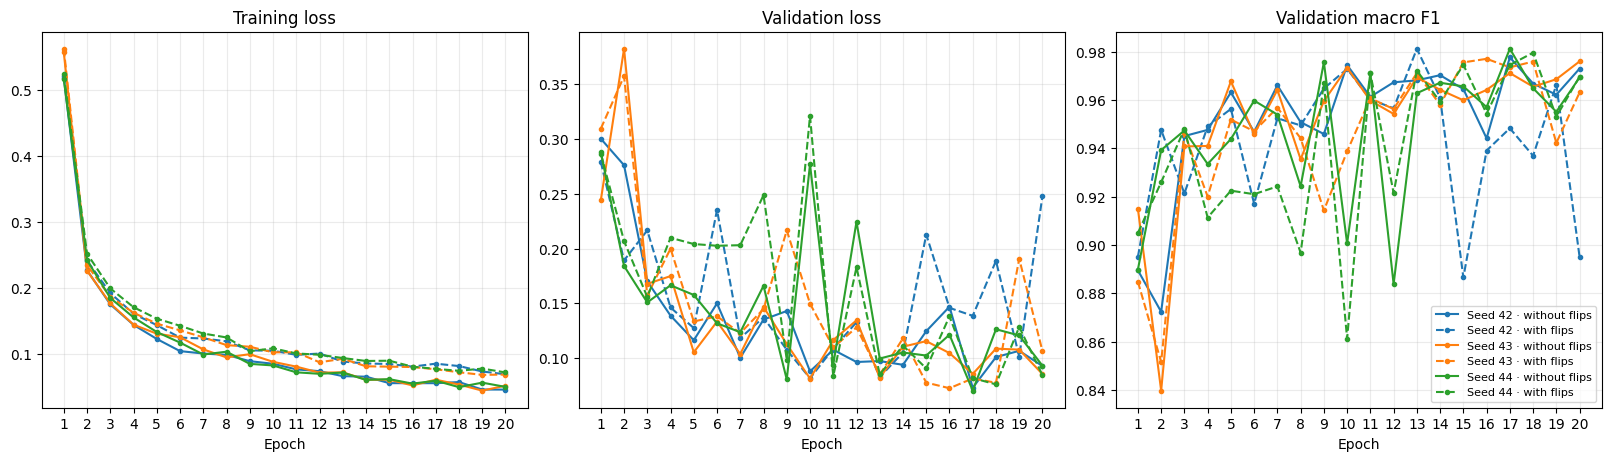

Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877/learning_curves.png
 seed         condition  best_epoch  accuracy  macro_f1  balanced_accuracy
   44 with_augmentation          18    0.9795    0.9795             0.9827


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")

curve_panels = [
    ("train_loss", "Training loss"),
    ("val_loss", "Validation loss"),
    ("val_macro_f1", "Validation macro F1"),
]
seed_colors = dict(zip(SEEDS, ("tab:blue", "tab:orange", "tab:green")))

for (seed, condition), run_dir in run_paths.items():
    history = pd.read_csv(run_dir / "epoch_history.csv")
    augmented = condition == "with_augmentation"
    label = f"Seed {seed} · {'with flips' if augmented else 'without flips'}"

    for ax, (column, title) in zip(axes, curve_panels):
        ax.plot(
            history["epoch"],
            history[column],
            color=seed_colors[seed],
            linestyle="--" if augmented else "-",
            marker=".",
            label=label,
        )
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_xticks(range(1, EPOCHS + 1))
        ax.grid(alpha=0.25)

axes[-1].legend(fontsize=8)
curves_path = RUNS_DIR / "learning_curves.png"
fig.savefig(curves_path, dpi=200)
plt.show()
plt.close(fig)

print("Saved:", curves_path)
print(
    validation_summary.loc[
        (validation_summary["seed"] == 44)
        & (validation_summary["condition"] == "with_augmentation")
    ].round(4).to_string(index=False)
)

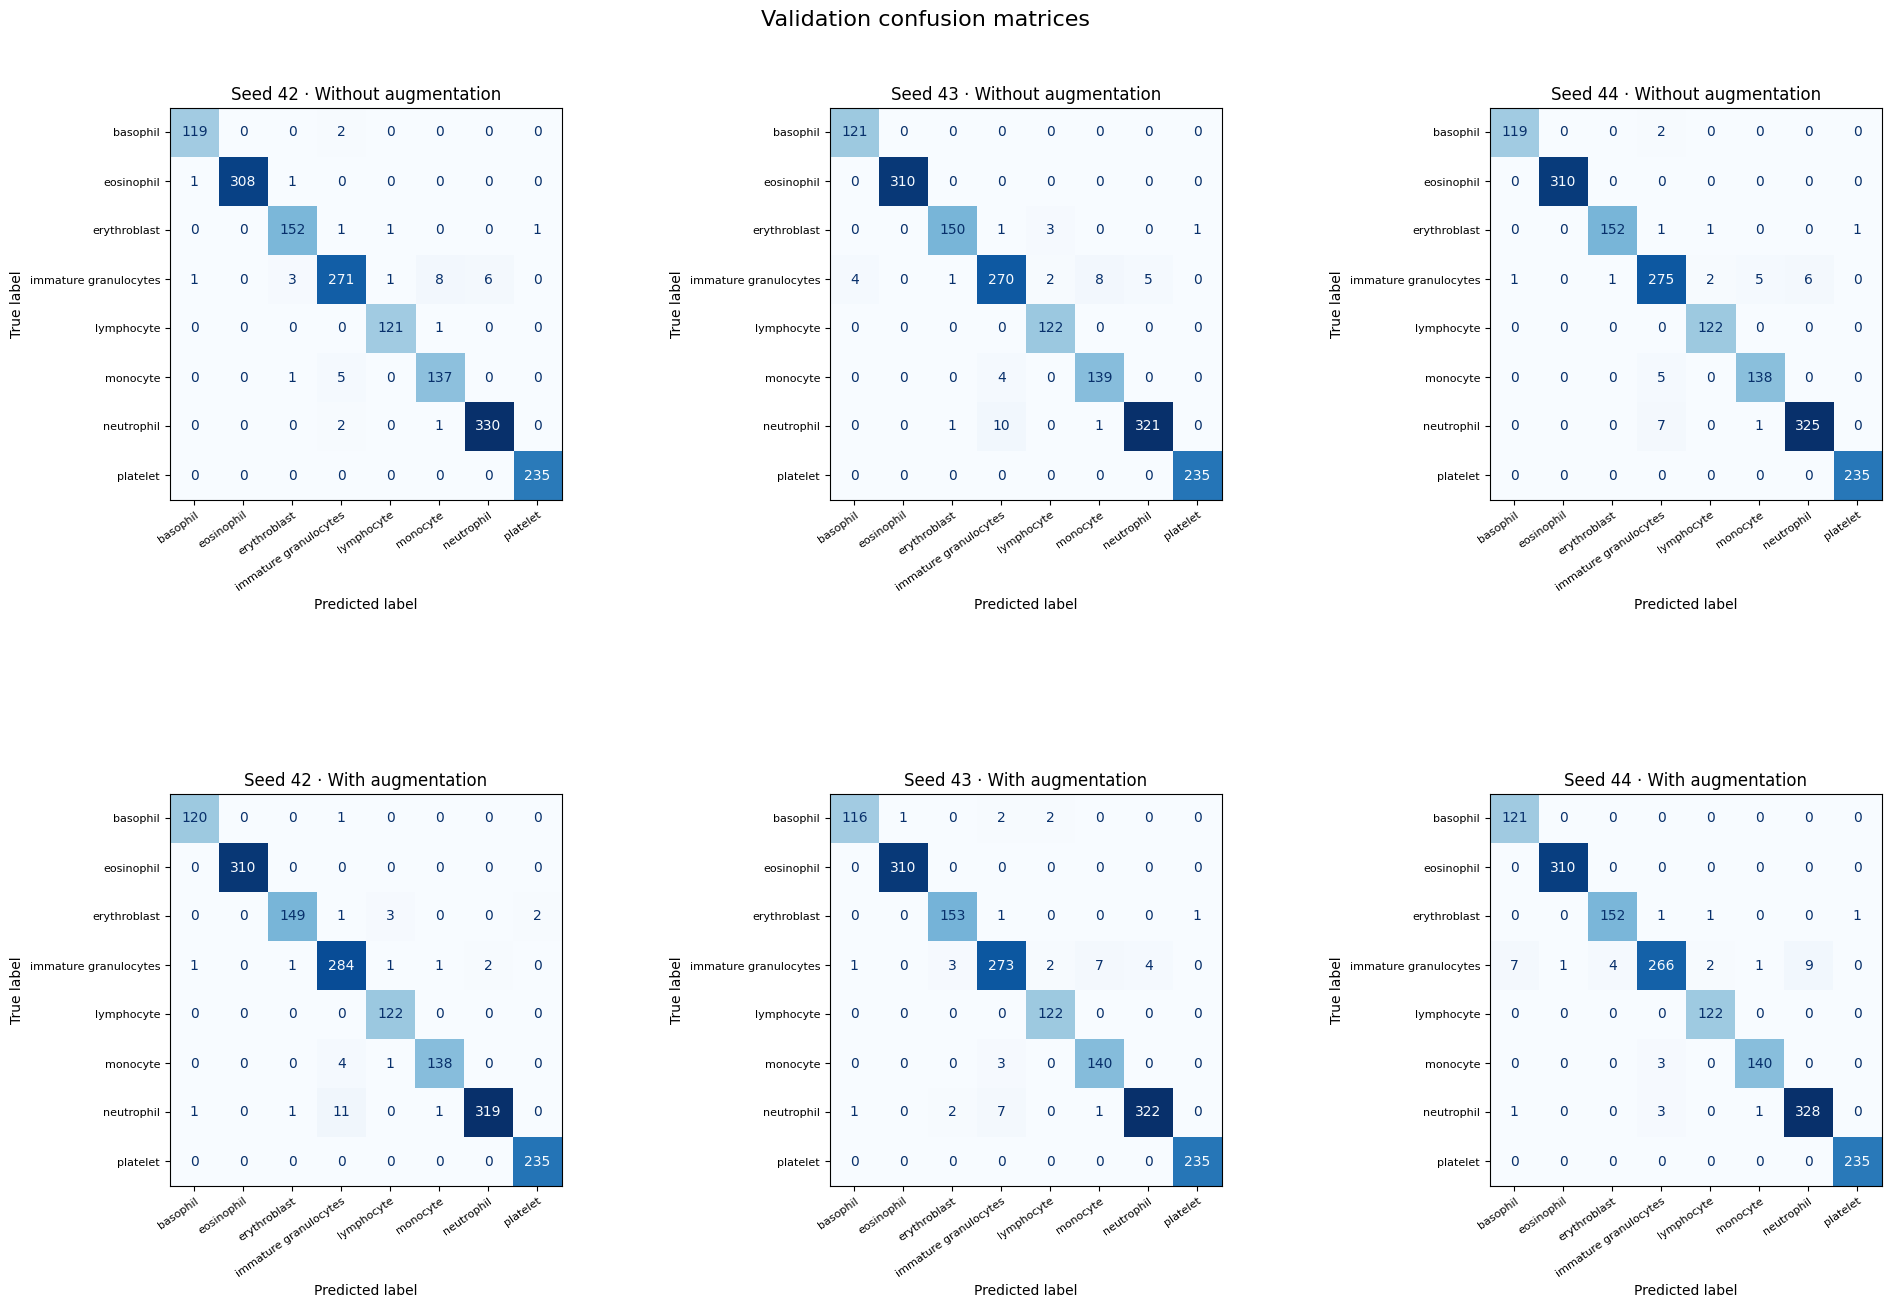

Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877/validation_confusion_matrices.png
Saved 6 matrix CSVs in the run folders.


In [31]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

matrix_labels = [class_names[class_id] for class_id in CLASS_IDS]
plot_labels = [label.split("(", 1)[0].strip() for label in matrix_labels]


def save_confusion_matrices(predictions_by_run, split_name):
    fig, axes = plt.subplots(
        len(CONDITIONS), len(SEEDS),
        figsize=(20, 14),
        layout="none",
    )
    fig.subplots_adjust(
        left=0.12, right=0.98, bottom=0.14, top=0.91,
        wspace=0.65, hspace=0.75,
    )

    for row, condition in enumerate(CONDITIONS):
        condition_label = (
            "With augmentation" if condition == "with_augmentation"
            else "Without augmentation"
        )

        for column, seed in enumerate(SEEDS):
            run_key = (seed, condition)
            predictions = predictions_by_run[run_key]
            counts = confusion_matrix(
                predictions["true_class_id"],
                predictions["predicted_class_id"],
                labels=CLASS_IDS,
            )

            counts_table = pd.DataFrame(
                counts, index=matrix_labels, columns=matrix_labels
            )
            counts_table.to_csv(
                run_paths[run_key] / f"{split_name}_confusion_matrix.csv",
                index_label="true_class",
            )

            ax = axes[row, column]
            ConfusionMatrixDisplay(
                confusion_matrix=counts,
                # display_labels=matrix_labels,
                display_labels=plot_labels,
            ).plot(ax=ax, cmap="Blues", colorbar=False)

            ax.tick_params(axis="both", labelsize=8)
            plt.setp(
                ax.get_xticklabels(),
                rotation=35,
                ha="right",
                rotation_mode="anchor",
            )
            ax.set_title(f"Seed {seed} · {condition_label}")

    fig.suptitle(f"{split_name.capitalize()} confusion matrices", fontsize=16)
    plot_path = RUNS_DIR / f"{split_name}_confusion_matrices.png"
    fig.savefig(plot_path, dpi=200)
    plt.show()
    plt.close(fig)

    print("Saved:", plot_path)
    print(f"Saved {len(predictions_by_run)} matrix CSVs in the run folders.")


validation_predictions = {}
validation_model = BloodCellCNN().to(device)

for run_key, run_dir in run_paths.items():
    checkpoint = torch.load(
        run_dir / "best_checkpoint.pt",
        map_location="cpu",
        weights_only=True,
    )
    validation_model.load_state_dict(checkpoint["model"])
    _, validation_predictions[run_key] = evaluate_model(
        validation_model, validation_loader
    )

save_confusion_matrices(validation_predictions, "validation")

In [32]:
# Freeze the experiment before test evaluation
frozen_checkpoints = []

for (seed, condition), run_dir in run_paths.items():
    checkpoint_path = run_dir / "best_checkpoint.pt"
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )

    assert (checkpoint["config_id"], checkpoint["seed"], checkpoint["condition"]) == (
        config_id, seed, condition
    ), checkpoint_path

    frozen_checkpoints.append({
        "seed": seed,
        "condition": condition,
        "selected_epoch": checkpoint["epoch"],
        "validation_macro_f1": checkpoint["validation_metrics"]["macro_f1"],
        "checkpoint": checkpoint_path.relative_to(RUNS_DIR).as_posix(),
        "sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
    })

assert len(frozen_checkpoints) == len(SEEDS) * len(CONDITIONS)

frozen_experiment = {
    "config_id": config_id,
    "configuration": run_config,
    "budget_decision": (
        "budget_decision": (
    "We extended the shared budget from 10 to 20 epochs because five of six "
    "runs selected epoch 9 or 10 under the 10-epoch budget. Under 20 epochs, "
    "selected epochs ranged from 13 to 20, so we froze 20 epochs for all six runs."
),
    ),
    "checkpoints": frozen_checkpoints,
}

freeze_path = RUNS_DIR / "frozen_experiment.json"
freeze_path.write_text(
    json.dumps(frozen_experiment, indent=2) + "\n", encoding="utf-8"
)

print(f"Frozen: {len(frozen_checkpoints)} checkpoints, {EPOCHS} epochs per run.")
print("Saved:", freeze_path)

Frozen: 6 checkpoints, 20 epochs per run.
Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877/frozen_experiment.json


## 10. Evaluate the frozen checkpoints on the test set

We evaluate the six checkpoints selected by validation macro F1 on the same 3,415 retained test images. We verify each checkpoint against the frozen experiment record and apply the same deterministic preprocessing in both conditions.

For each seed and condition, we report accuracy, macro F1, balanced accuracy, and per-class precision, recall, and F1. We save one prediction per retained test image with its original test row ID, true class, and predicted class. We also display and save labeled confusion matrices and export their counts as CSVs.

 seed            condition  selected_epoch  accuracy  macro_f1  balanced_accuracy
   42 without_augmentation              17    0.9757    0.9761             0.9770
   42    with_augmentation              13    0.9654    0.9665             0.9660
   43 without_augmentation              20    0.9725    0.9718             0.9743
   43    with_augmentation              16    0.9742    0.9743             0.9738
   44 without_augmentation              17    0.9751    0.9754             0.9731
   44    with_augmentation              18    0.9728    0.9718             0.9724

Saved predictions for 3,415 test images per run.


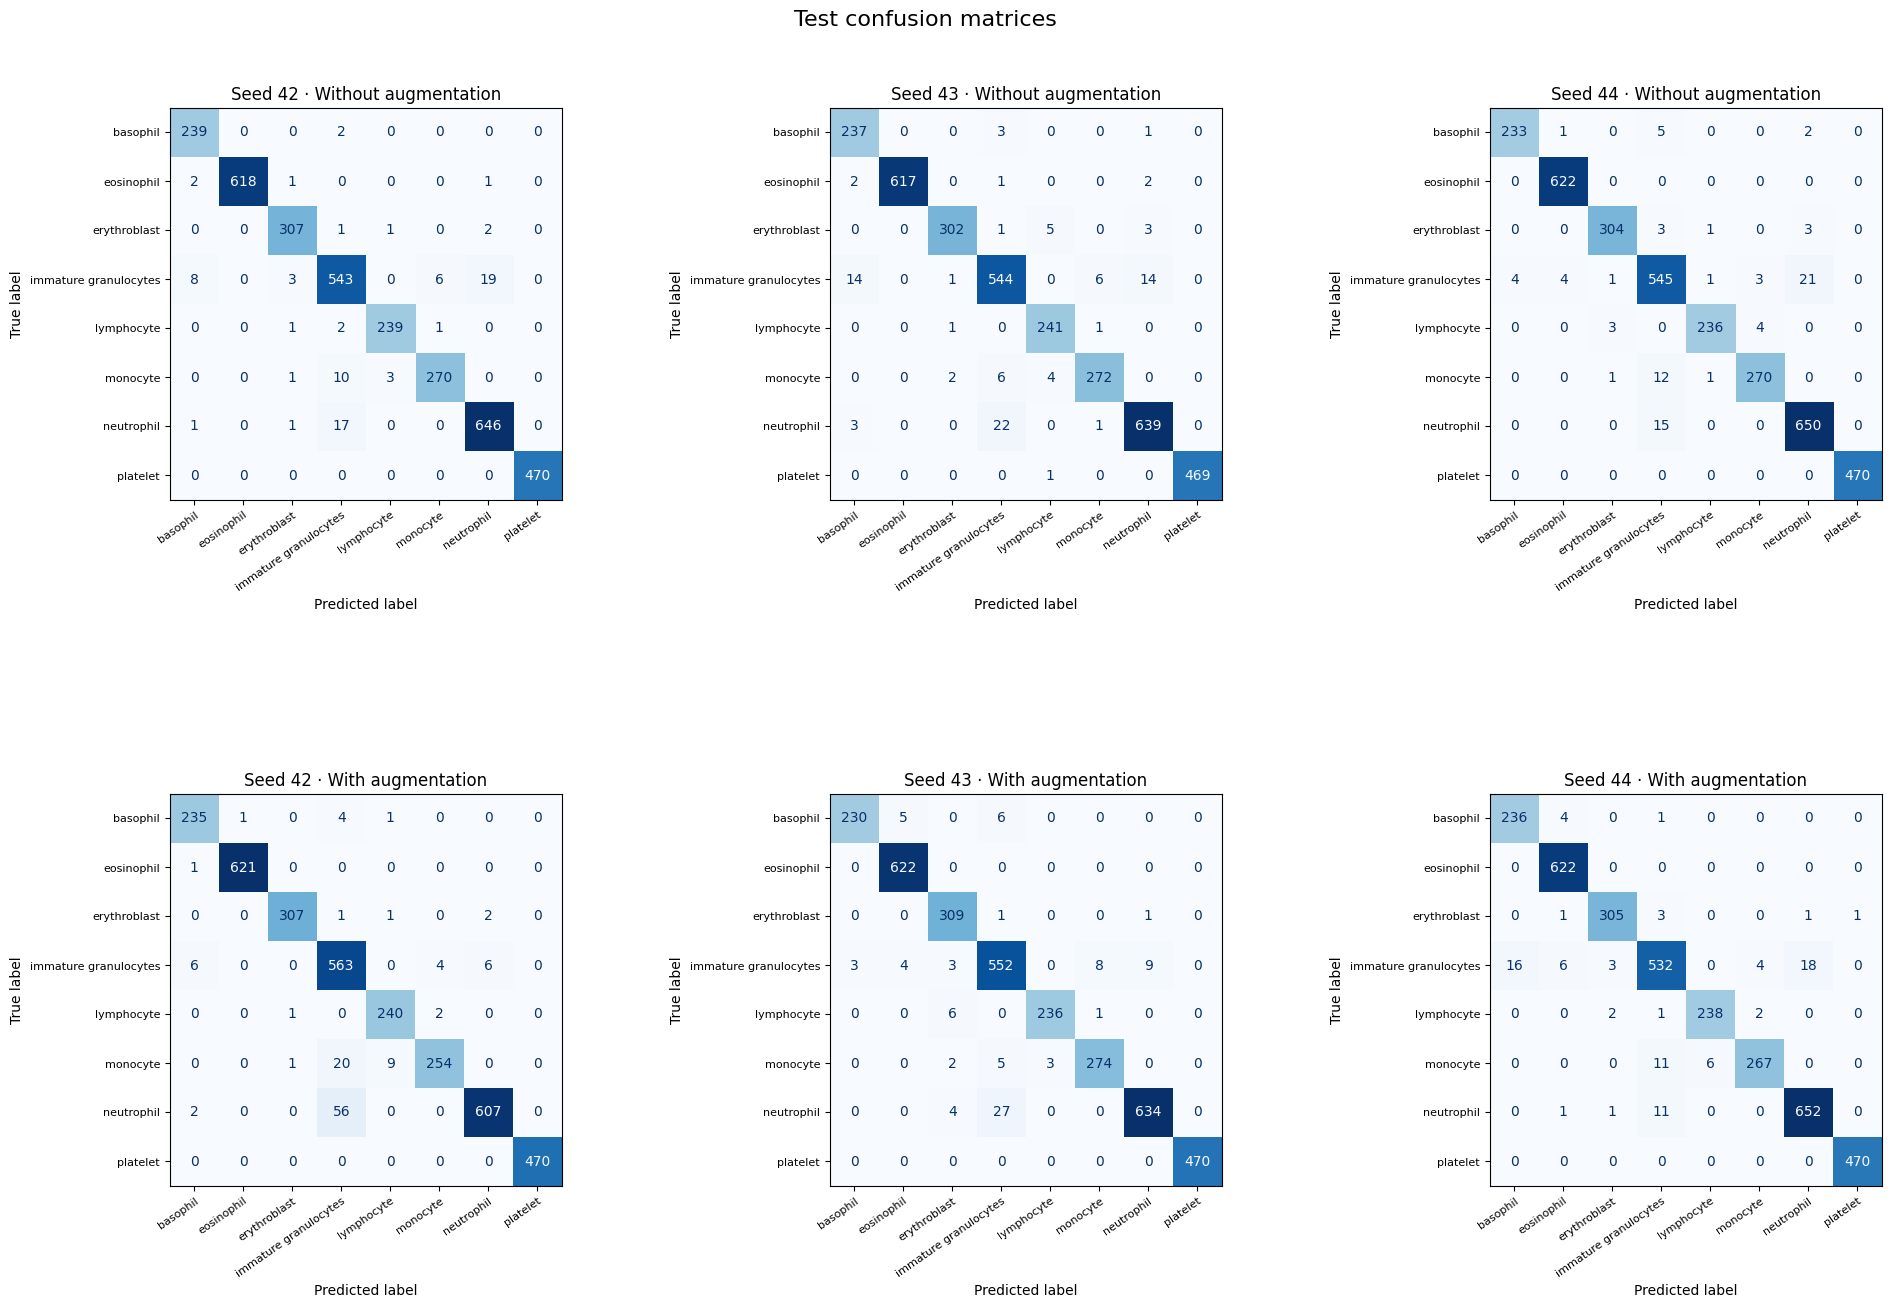

Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877/test_confusion_matrices.png
Saved 6 matrix CSVs in the run folders.


In [33]:
frozen = json.loads(freeze_path.read_text(encoding="utf-8"))
assert frozen["config_id"] == config_id, "The current configuration does not match the freeze record."

frozen_paths = {}
for entry in frozen["checkpoints"]:
    run_key = (entry["seed"], entry["condition"])
    checkpoint_path = RUNS_DIR / entry["checkpoint"]

    assert run_key not in frozen_paths, run_key
    assert checkpoint_path == run_paths[run_key] / "best_checkpoint.pt", checkpoint_path
    assert hashlib.sha256(checkpoint_path.read_bytes()).hexdigest() == entry["sha256"], (
        f"Checkpoint changed after freezing: {checkpoint_path}"
    )
    frozen_paths[run_key] = checkpoint_path

assert frozen_paths.keys() == run_paths.keys(), "The freeze record must cover all six runs."

test_dataset = RetainedBloodMNIST("test", deterministic_transform)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

test_model = BloodCellCNN().to(device)
test_rows = []
test_class_rows = []
test_predictions = {}

for (seed, condition), checkpoint_path in frozen_paths.items():
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    test_model.load_state_dict(checkpoint["model"])
    metrics, predictions = evaluate_model(test_model, test_loader)

    assert np.array_equal(
        predictions["original_row_id"].to_numpy(), retained_indices["test"]
    ), (seed, condition)

    predictions["true_class"] = predictions["true_class_id"].map(class_names)
    predictions["predicted_class"] = predictions["predicted_class_id"].map(class_names)
    predictions.to_csv(
        checkpoint_path.parent / "test_predictions.csv", index=False
    )
    test_predictions[(seed, condition)] = predictions

    test_rows.append({
        "seed": seed,
        "condition": condition,
        "selected_epoch": checkpoint["epoch"],
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "balanced_accuracy": metrics["balanced_accuracy"],
    })
    for class_metrics in metrics["per_class"]:
        test_class_rows.append({
            "seed": seed,
            "condition": condition,
            **class_metrics,
        })

test_summary = pd.DataFrame(test_rows)
test_per_class = pd.DataFrame(test_class_rows)

test_summary.to_csv(RUNS_DIR / "test_summary.csv", index=False)
test_per_class.to_csv(RUNS_DIR / "test_per_class.csv", index=False)

print(test_summary.round(4).to_string(index=False))
print(f"\nSaved predictions for {len(test_dataset):,} test images per run.")
save_confusion_matrices(test_predictions, "test")

In [53]:
test_metric_names = ["accuracy", "macro_f1", "balanced_accuracy"]
without_aug, with_aug = CONDITIONS

test_by_condition = (
    test_summary.groupby("condition", sort=False)[test_metric_names]
    .agg(["mean", "std"])
    .mul(100)
)
test_by_condition.columns = [
    f"{metric}_{statistic}_pct"
    for metric, statistic in test_by_condition.columns
]

paired_test_gains = pd.DataFrame(index=pd.Index(SEEDS, name="seed"))

for metric in test_metric_names:
    scores = test_summary.pivot(index="seed", columns="condition", values=metric)
    paired_test_gains[f"{metric}_gain_pp"] = (
        scores[with_aug] - scores[without_aug]
    ) * 100

mean_class_f1 = (
    test_per_class.groupby(["class_id", "class_name", "condition"])["f1"]
    .mean()
    .unstack("condition")
    .mul(100)
)
class_comparison = mean_class_f1[[without_aug, with_aug]].rename(columns={
    without_aug: "without_augmentation_mean_f1_pct",
    with_aug: "with_augmentation_mean_f1_pct",
})
class_comparison["f1_gain_pp"] = mean_class_f1[with_aug] - mean_class_f1[without_aug]
class_comparison = class_comparison.sort_values("f1_gain_pp", ascending=False)

test_by_condition.to_csv(RUNS_DIR / "test_mean_std_by_condition.csv")
paired_test_gains.to_csv(RUNS_DIR / "test_paired_gains.csv")
class_comparison.to_csv(RUNS_DIR / "test_class_f1_comparison.csv")

print("Test mean and standard deviation in percent")
display(test_by_condition.round(2))

print("Paired test gains in percentage points")
display(paired_test_gains.round(2))
print(f"Mean paired macro F1 gain: {paired_test_gains['macro_f1_gain_pp'].mean():+.2f} pp")

print("\nMean test F1 by class, with paired gains in percentage points")
display(class_comparison.round(2))

Test mean and standard deviation in percent


,accuracy_mean_pct,accuracy_std_pct,macro_f1_mean_pct,macro_f1_std_pct,balanced_accuracy_mean_pct,balanced_accuracy_std_pct
condition,,,,,,
without_augmentation,97.44,0.17,97.44,0.23,97.48,0.20
with_augmentation,97.08,0.47,97.09,0.40,97.07,0.42


Paired test gains in percentage points


,accuracy_gain_pp,macro_f1_gain_pp,balanced_accuracy_gain_pp
seed,,,
42,-1.02,-0.96,-1.10
43,0.18,0.25,-0.05
44,-0.23,-0.36,-0.08


Mean paired macro F1 gain: -0.35 pp

Mean test F1 by class, with paired gains in percentage points


,condition,without_augmentation_mean_f1_pct,with_augmentation_mean_f1_pct,f1_gain_pp
class_id,class_name,,,
2,erythroblast,98.07,98.14,0.08
7,platelet,99.96,99.96,0.00
0,basophil,96.74,96.56,-0.17
1,eosinophil,99.62,99.39,-0.24
4,lymphocyte,97.95,97.61,-0.34
6,neutrophil,96.80,96.44,-0.36
3,"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",94.09,93.31,-0.78
5,monocyte,96.32,95.30,-1.02


In [54]:
# Misclassification analysis on the test set
short_names = {i: class_names[i].split("(", 1)[0].strip() for i in CLASS_IDS}

test_preds = {
    run_key: pd.read_csv(run_dir / "test_predictions.csv")
    for run_key, run_dir in run_paths.items()
}

# Errors per run
error_summary = pd.DataFrame([
    {
        "seed": seed,
        "condition": condition,
        "errors": int((p["true_class_id"] != p["predicted_class_id"]).sum()),
        "error_rate_pct": 100 * (p["true_class_id"] != p["predicted_class_id"]).mean(),
    }
    for (seed, condition), p in test_preds.items()
])
display(error_summary.round(2))

# Most common (true class -> predicted class) mistakes, averaged over seeds
pair_frames = []
for (seed, condition), p in test_preds.items():
    wrong = p[p["true_class_id"] != p["predicted_class_id"]]
    counts = (
        wrong.groupby(["true_class_id", "predicted_class_id"])
        .size().rename("count").reset_index()
    )
    counts["condition"] = condition
    pair_frames.append(counts)

mean_pairs = (
    pd.concat(pair_frames)
    .groupby(["condition", "true_class_id", "predicted_class_id"])["count"]
    .sum().div(len(SEEDS)).rename("mean_errors").reset_index()
)

pair_table = mean_pairs.pivot_table(
    index=["true_class_id", "predicted_class_id"],
    columns="condition", values="mean_errors", fill_value=0,
)
pair_table["total"] = pair_table.sum(axis=1)
pair_table = pair_table.sort_values("total", ascending=False).head(10).reset_index()
pair_table.insert(0, "true_class", pair_table["true_class_id"].map(short_names))
pair_table.insert(1, "predicted_as", pair_table["predicted_class_id"].map(short_names))
pair_table = pair_table.drop(columns=["true_class_id", "predicted_class_id", "total"])

pairs_path = RUNS_DIR / "test_confusion_pairs.csv"
pair_table.to_csv(pairs_path, index=False)

print("Top 10 confusions: mean errors per seed")
display(pair_table.round(2))
print("Saved:", pairs_path)

,seed,condition,errors,error_rate_pct
0,42,without_augmentation,83,2.43
1,42,with_augmentation,118,3.46
2,43,without_augmentation,94,2.75
3,43,with_augmentation,88,2.58
4,44,without_augmentation,85,2.49
5,44,with_augmentation,93,2.72


Top 10 confusions: mean errors per seed


condition,true_class,predicted_as,with_augmentation,without_augmentation
0,neutrophil,immature granulocytes,31.33,18.00
1,immature granulocytes,neutrophil,11.00,18.00
2,monocyte,immature granulocytes,12.00,9.33
3,immature granulocytes,basophil,8.33,8.67
4,immature granulocytes,monocyte,5.33,5.00
5,monocyte,lymphocyte,6.00,2.67
6,basophil,immature granulocytes,3.67,3.33
7,lymphocyte,erythroblast,3.00,1.67
8,immature granulocytes,eosinophil,3.33,1.33
9,erythroblast,neutrophil,1.33,2.67


Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877/test_confusion_pairs.csv


## 11. Compare augmentation results and verify saved files

We report the test results for each seed and summarize accuracy, macro F1, and balanced accuracy as mean ± standard deviation across the three seeds.

For each seed, we subtract the score without augmentation from the score with augmentation and report the difference in percentage points. We check whether augmentation helped consistently across seeds and compare mean per-class F1 to identify which blood cell classes improved or worsened.

We save the comparison tables and verify that the expected experiment files exist in `results/`.

Misclassified by all six runs: 27 of 3415 test images


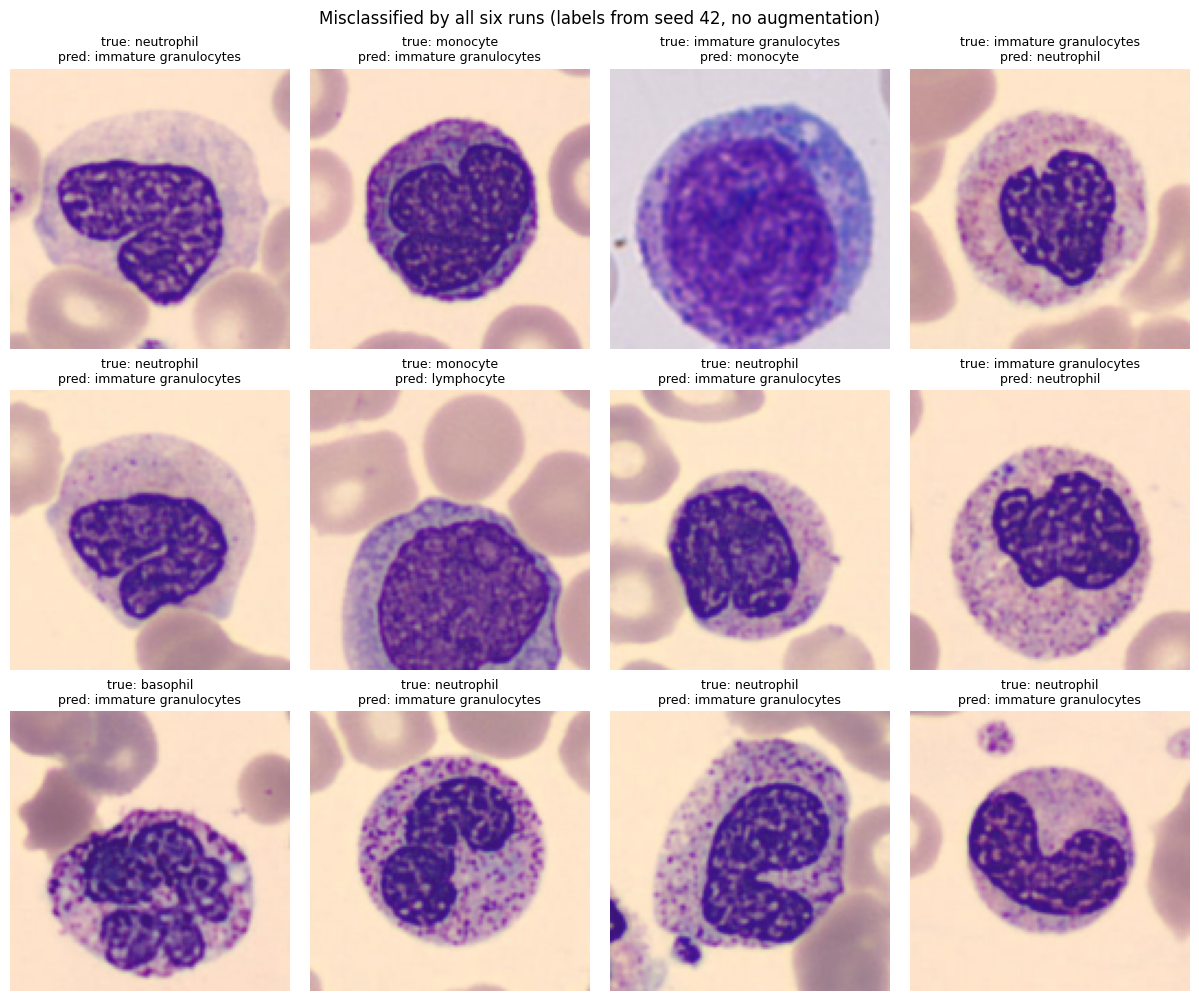

Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877/test_always_misclassified.png


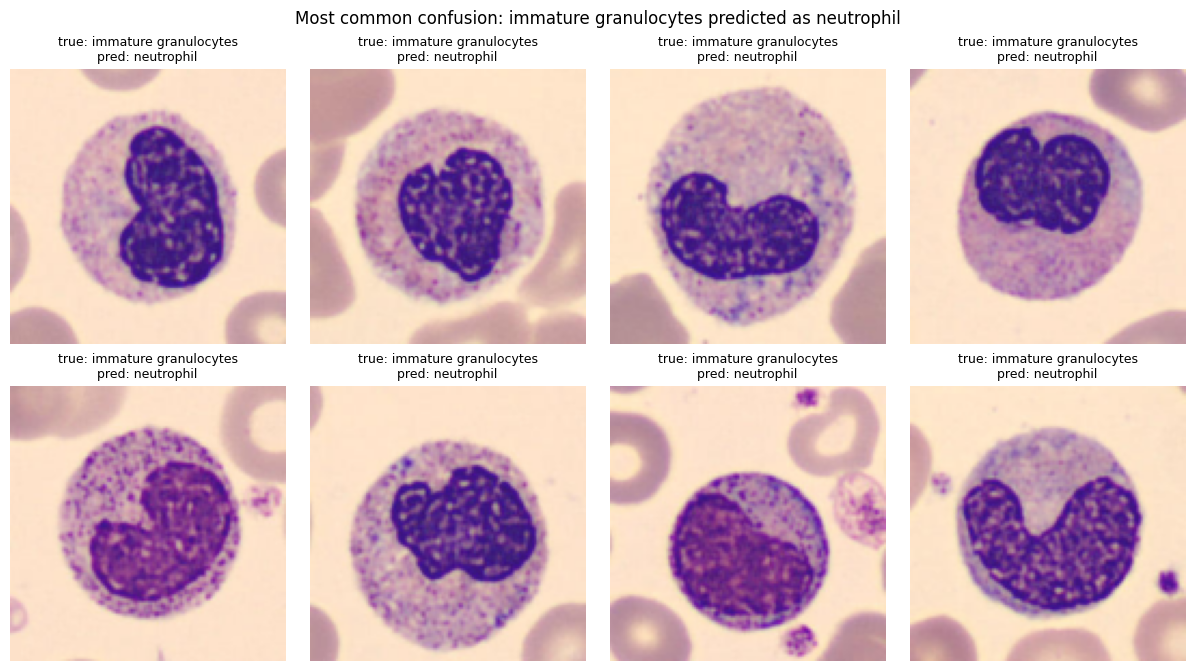

Saved: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877/test_top_confusion_examples.png


In [55]:
# Show misclassified test images
test_images = official_datasets["test"].imgs
reference = test_preds[(SEEDS[0], "without_augmentation")].set_index("original_row_id")


def show_grid(row_ids, title, path, columns=4):
    rows = int(np.ceil(len(row_ids) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 3.3 * rows),
                             layout="constrained")
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, row_id in zip(np.atleast_1d(axes).flat, row_ids):
        ax.imshow(test_images[row_id])
        true_id = reference.loc[row_id, "true_class_id"]
        pred_id = reference.loc[row_id, "predicted_class_id"]
        ax.set_title(f"true: {short_names[true_id]}\npred: {short_names[pred_id]}",
                     fontsize=9)
    fig.suptitle(title, fontsize=12)
    fig.savefig(path, dpi=200)
    plt.show()
    plt.close(fig)
    print("Saved:", path)


# (a) Images that all six models got wrong
wrong_sets = [
    set(p.loc[p["true_class_id"] != p["predicted_class_id"], "original_row_id"])
    for p in test_preds.values()
]
always_wrong = sorted(set.intersection(*wrong_sets))
print(f"Misclassified by all six runs: {len(always_wrong)} of {len(retained_indices['test'])} test images")

if always_wrong:
    show_grid(
        always_wrong[:12],
        f"Misclassified by all six runs (labels from seed {SEEDS[0]}, no augmentation)",
        RUNS_DIR / "test_always_misclassified.png",
    )

# (b) Examples of the single most common confusion (no augmentation)
top = (
    mean_pairs[mean_pairs["condition"] == "without_augmentation"]
    .sort_values("mean_errors", ascending=False).iloc[0]
)
top_true, top_pred = int(top["true_class_id"]), int(top["predicted_class_id"])
example_rows = reference[
    (reference["true_class_id"] == top_true)
    & (reference["predicted_class_id"] == top_pred)
].index.tolist()[:8]

if example_rows:
    show_grid(
        example_rows,
        f"Most common confusion: {short_names[top_true]} predicted as {short_names[top_pred]}",
        RUNS_DIR / "test_top_confusion_examples.png",
    )

In [57]:
# Recall for immature granulocytes (class 3) with 95% bootstrap intervals
IG_ID = 3
preds = {}
for (seed, condition), run_dir in run_paths.items():
    p = pd.read_csv(run_dir / "test_predictions.csv")
    preds[(seed, condition)] = p["predicted_class_id"].to_numpy()
    y_true = p["true_class_id"].to_numpy()          # same images for every run

ig = np.flatnonzero(y_true == IG_ID)
print(f"IG test images: {len(ig)}")

# per-image fraction of seeds that classify each IG image correctly
hit = {
    cond: np.mean([preds[(s, cond)][ig] == IG_ID for s in SEEDS], axis=0)
    for cond in CONDITIONS
}

rng = np.random.default_rng(0)
B = 10_000
idx = rng.integers(0, len(ig), size=(B, len(ig)))   # shared resamples

def interval(values):
    return np.percentile(values, [2.5, 97.5]) * 100

rows = []
for cond in CONDITIONS:
    boot = hit[cond][idx].mean(axis=1)
    lo, hi = interval(boot)
    rows.append({"condition": cond, "recall_pct": hit[cond].mean() * 100,
                 "ci_low": lo, "ci_high": hi})

diff = (hit[with_aug] - hit[without_aug])
lo, hi = interval(diff[idx].mean(axis=1))
rows.append({"condition": "with minus without (pp)", "recall_pct": diff.mean() * 100,
             "ci_low": lo, "ci_high": hi})

ig_recall = pd.DataFrame(rows)
display(ig_recall.round(2))
ig_recall.to_csv(RUNS_DIR / "test_ig_recall_ci.csv", index=False)

for (seed, condition), pr in preds.items():
    print(f"seed {seed} | {condition:21s} | IG recall {100 * np.mean(pr[ig] == IG_ID):.2f}%")

IG test images: 579


,condition,recall_pct,ci_low,ci_high
0,without_augmentation,93.96,92.29,95.51
1,with_augmentation,94.82,93.32,96.26
2,with minus without (pp),0.86,-0.06,1.78


seed 42 | without_augmentation  | IG recall 93.78%
seed 42 | with_augmentation     | IG recall 97.24%
seed 43 | without_augmentation  | IG recall 93.96%
seed 43 | with_augmentation     | IG recall 95.34%
seed 44 | without_augmentation  | IG recall 94.13%
seed 44 | with_augmentation     | IG recall 91.88%


In [59]:
# Immature granulocyte recall with paired 95% bootstrap intervals
IG_ID = 3
without_aug, with_aug = CONDITIONS
reference = test_preds[(SEEDS[0], without_aug)].set_index("original_row_id")
ig_rows = reference.index[reference["true_class_id"].eq(IG_ID)]

hits_by_condition = {}
for condition in CONDITIONS:
    seed_hits = []
    for seed in SEEDS:
        predictions = test_preds[(seed, condition)].set_index("original_row_id")
        hits = predictions.loc[ig_rows, "predicted_class_id"].eq(IG_ID).to_numpy()
        seed_hits.append(hits)
        print(f"Seed {seed} | {condition} | IG recall: {100 * hits.mean():.2f}%")
    hits_by_condition[condition] = np.mean(seed_hits, axis=0)

rng = np.random.default_rng(0)
sample_rows = rng.integers(0, len(ig_rows), size=(10_000, len(ig_rows)))

comparisons = {
    without_aug: hits_by_condition[without_aug],
    with_aug: hits_by_condition[with_aug],
    "with minus without (pp)": (
        hits_by_condition[with_aug] - hits_by_condition[without_aug]
    ),
}

rows = []
for condition, hits in comparisons.items():
    bootstrap_means = hits[sample_rows].mean(axis=1)
    low, high = 100 * np.percentile(bootstrap_means, [2.5, 97.5])
    rows.append({
        "condition": condition,
        "recall_pct": 100 * hits.mean(),
        "ci_low": low,
        "ci_high": high,
    })

ig_recall = pd.DataFrame(rows)
ig_recall.to_csv(RUNS_DIR / "test_ig_recall_ci.csv", index=False)
print(f"Immature granulocyte test images: {len(ig_rows)}")
display(ig_recall.round(2))

Seed 42 | without_augmentation | IG recall: 93.78%
Seed 43 | without_augmentation | IG recall: 93.96%
Seed 44 | without_augmentation | IG recall: 94.13%
Seed 42 | with_augmentation | IG recall: 97.24%
Seed 43 | with_augmentation | IG recall: 95.34%
Seed 44 | with_augmentation | IG recall: 91.88%
Immature granulocyte test images: 579


,condition,recall_pct,ci_low,ci_high
0,without_augmentation,93.96,92.29,95.51
1,with_augmentation,94.82,93.32,96.26
2,with minus without (pp),0.86,-0.06,1.78


In [58]:
expected_files = [
    RESULTS_DIR / name
    for name in (
        "split_manifest.json",
        "bloodmnist_class_grid.png",
        "class_distribution.csv",
        "class_distribution.png",
        "normalization.json",
        "augmentation_preview.png",
        "run_config.json",
    )
]

expected_files.extend(
    RUNS_DIR / name
    for name in (
        "validation_summary.csv",
        "validation_per_class.csv",
        "learning_curves.png",
        "validation_confusion_matrices.png",
        "frozen_experiment.json",
        "test_summary.csv",
        "test_per_class.csv",
        "test_confusion_matrices.png",
        "test_mean_std_by_condition.csv",
        "test_paired_gains.csv",
        "test_class_f1_comparison.csv",
        "test_confusion_pairs.csv",
        "test_always_misclassified.png",
        "test_top_confusion_examples.png",
        "test_ig_recall_ci.csv",
    )
)

for run_dir in run_paths.values():
    expected_files.extend(
        run_dir / name
        for name in (
            "progress.pt",
            "best_checkpoint.pt",
            "epoch_history.csv",
            "validation_confusion_matrix.csv",
            "test_confusion_matrix.csv",
            "test_predictions.csv",
        )
    )

missing_or_empty = [
    path for path in expected_files
    if not path.is_file() or path.stat().st_size == 0
]

assert not missing_or_empty, "\n".join(str(path) for path in missing_or_empty)

print(f"Verified {len(expected_files)} nonempty files.")
print("Results folder:", RESULTS_DIR)
print("Experiment folder:", RUNS_DIR)

Verified 58 nonempty files.
Results folder: /home/jovyan/BloodMNIST_Part_A_outputs/results
Experiment folder: /home/jovyan/BloodMNIST_Part_A_outputs/results/runs/404efcfe5a8be877


### Interpretation

Across three paired seeds with a 20-epoch budget, the CNN achieved a mean test macro F1 of **97.44% ± 0.23** without augmentation and **97.09% ± 0.40** with random horizontal and vertical flips. The paired change in macro F1 was **−0.96, +0.25, and −0.36 percentage points** for seeds 42, 43, and 44, with a mean of **−0.35 percentage points**. Accuracy changed by −1.02, +0.18, and −0.23 points, and balanced accuracy fell slightly in all three pairs (mean −0.41 points). Seed 42 accounts for most of the mean gap, and on validation macro F1 the flipped runs were slightly ahead on average (97.92% vs 97.82%). With only three seeds, we cannot distinguish this difference from seed-to-seed variation.

Mean test F1 was lower with flips for six of the eight classes, with the largest drops for monocytes (−1.02 points) and immature granulocytes (−0.78). Erythroblasts improved slightly (+0.08), and platelets were unchanged.

An earlier run with a 10-epoch budget showed a larger deficit for flips (mean −1.45 points), but five of those six runs selected their best checkpoint at epoch 9 or 10. Extending training to 20 epochs moved the selected epochs to between 13 and 20 and narrowed the gap, which suggests the 10-epoch result partly reflected under-training. Training loss was still falling at epoch 20, and one run (seed 43 without flips) selected the final epoch, so we cannot claim full convergence.

In this setup, flips alone did not improve test performance on the retained BloodMNIST split, and any harm is small. The Part B model, which used flips plus rotation, reached 98.8%, but it differs from Part A in more than augmentation, so the two are not a controlled comparison. The retained splits passed the exact pixel duplicate check. Patient and source overlap could not be verified from the archive, and near-duplicate overlap was not tested.